<a href="https://colab.research.google.com/github/marcelosantosjunior2027/IFOOD_GENAI_PORTIF-LIO/blob/main/simulador_de_curva_de_decl_nio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

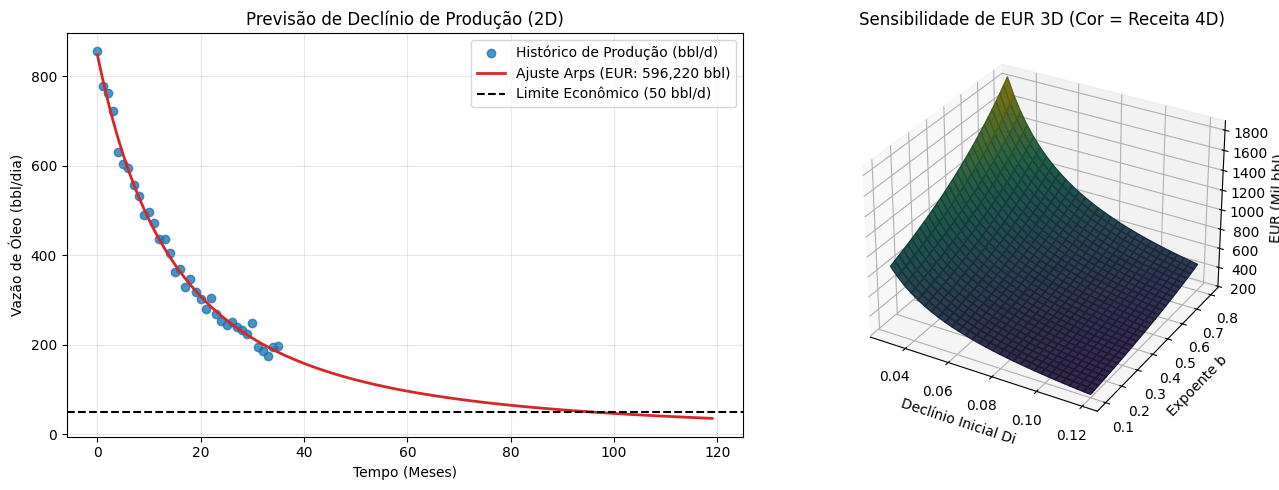

In [ ]:
# AUTOR DO PROJETO: MARCELO DE OLIVEIRA SANTOS JUNIOR
# SIMULAÇÃO DE ANÁLISE DE CURVA DE DECLÍNIO
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def hyperbolic_decline(t: np.ndarray, qi: float, di: float, b: float) -> np.ndarray:
    return qi / np.power(1.0 + b * di * t, 1.0 / b)

def cumulative_production(qi: float, di: float, b: float, q_econ: float) -> float:
    term = np.power(qi / q_econ, 1.0 - b)
    return (qi / ((1.0 - b) * di)) * (1.0 - (1.0 / term)) * 30.4375

# 1. Dados simulados realistas (36 meses de histórico com ruído operacional)
rng = np.random.default_rng(42)
months_hist = np.arange(0, 36)
rates_hist = hyperbolic_decline(months_hist, qi=850.0, di=0.065, b=0.45) + rng.normal(0, 18, 36)

# 2. Ajuste não-linear
popt, _ = curve_fit(
    hyperbolic_decline,
    months_hist,
    rates_hist,
    p0=[rates_hist[0], 0.05, 0.5],
    bounds=([0, 1e-4, 0.01], [5000, 1.0, 0.99])
)
qi_fit, di_fit, b_fit = popt

# 3. Projeção para 120 meses e cálculo de EUR (corte econômico = 50 bbl/d)
months_proj = np.arange(0, 120)
rates_proj = hyperbolic_decline(months_proj, qi_fit, di_fit, b_fit)
eur_bbl = cumulative_production(qi_fit, di_fit, b_fit, q_econ=50.0)

# 4. Visualização 2D + Superfície 3D/4D
fig = plt.figure(figsize=(14, 5))

# Gráfico 2D: Histórico e Previsão
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(months_hist, rates_hist, color="#1f77b4", label="Histórico de Produção (bbl/d)", alpha=0.8)
ax1.plot(months_proj, rates_proj, color="#d62728", lw=2, label=f"Ajuste Arps (EUR: {eur_bbl:,.0f} bbl)")
ax1.axhline(50.0, color="black", linestyle="--", label="Limite Econômico (50 bbl/d)")
ax1.set_title("Previsão de Declínio de Produção (2D)")
ax1.set_xlabel("Tempo (Meses)")
ax1.set_ylabel("Vazão de Óleo (bbl/dia)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gráfico 3D/4D: Sensibilidade de EUR (Di x b x Volume x Taxa de Recuperação)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
di_grid = np.linspace(0.03, 0.12, 30)
b_grid = np.linspace(0.1, 0.8, 30)
DI, B = np.meshgrid(di_grid, b_grid)
EUR_GRID = cumulative_production(qi_fit, DI, B, q_econ=50.0) / 1e3  # Milhares de barris
VPL_PROXY = EUR_GRID * 42.0  # 4ª dimensão: Receita Líquida Estimada (US$ k)

surf = ax2.plot_surface(DI, B, EUR_GRID, facecolors=plt.cm.viridis(VPL_PROXY / VPL_PROXY.max()), alpha=0.9)
ax2.set_title("Sensibilidade de EUR 3D (Cor = Receita 4D)")
ax2.set_xlabel("Declínio Inicial Di")
ax2.set_ylabel("Expoente b")
ax2.set_zlabel("EUR (Mil bbl)")

plt.tight_layout()
plt.show()